# K562 CRISPRi Perturb-seq prediction — v0.5-basin-lock

**Tag:** `v0.5-basin-lock`

**Setup.** Replogle 2022 Essential K562 (310 385 cells × 8 563 genes, 10 691 non-targeting controls). HVG 2000 on controls + mandatory inclusion of perturbation targets (3 559 kept). scVI(d=15) + ESM energy drift + NB rate model fit on CONTROLS ONLY. Mean per-cell latent `J` across controls = control-basin operator; `grad_eta` evaluated at the control centroid.

**Prediction.** For each KD g with ≥ 50 cells, push `b_g` in η-space is a unit vector along gene g scaled by observed log-fold change of g itself. Steady-state shift via linear response:
`δx_pred = grad_eta @ (−J_mean⁻¹) @ pinv(grad_eta) @ b_g` (equivalent to tangent-restricted gene-space J⁻¹ when the Fisher-information tangent is spanned by `grad_eta`; Tikhonov ε = 1e-6·‖J‖_F / d).

**Score.** `cos(δx_pred, δx_obs)` on genes with top-50% Fisher confidence (per-gene held-out NB NLL). Baselines: 10 random unit vectors per KD, DE-only (`δx = b_g`), GEARS skipped (not installable in budget — V2_PLAN §9e).

No archetype decomposition, no pseudotime, no prior. This notebook reproduces §2-7 from the stored outputs — no refitting.

In [1]:
import warnings
warnings.filterwarnings('ignore')
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO = Path.cwd().resolve()
if REPO.name == 'notebooks':
    REPO = REPO.parent
OUT = REPO / 'benchmarks' / 'perturbseq_k562'

pk = pd.read_csv(OUT / 'per_knockdown.csv')
sb = pd.read_csv(OUT / 'baseline_comparison.csv')
dc = pd.read_csv(OUT / 'driver_check.csv')
meta = json.loads((OUT / 'run_meta.json').read_text())
print(f"tag = {meta['tag']}  n_kd = {meta['n_kd_evaluated']}  n_linear = {meta['n_kd_linear']}")
print(f"symmetry median = {meta['symmetry_median']:.2e}  rate-model NLL = {meta['rate_model_nll']:.3f}")

tag = v0.5-basin-lock  n_kd = 1661  n_linear = 831
symmetry median = 1.42e-07  rate-model NLL = -4.488


## 2. Per-knockdown table (head)

Columns: `gene`, `n_kd_cells`, `lfc_g` (push scale), `mag_pred` and `mag_obs` (||δx|| on ok-mask), `cos_scjdo2`, `cos_de_only`, `cos_random_mean/std`, `mean_fisher_conf`, `linear_regime` flag.

In [2]:
pk.head(15).round(3)

,gene,n_kd_cells,lfc_g,mag_pred,mag_obs,cos_scjdo2,cos_de_only,cos_random_mean,cos_random_std,ok_mask_size,mean_fisher_conf,linear_regime
0,RPL3,1996,-0.410,0.012,1.601,-0.043,0.001,0.001,0.020,1780,10.824,True
1,NCBP2,992,-0.373,0.009,9.073,0.129,NaN,0.007,0.023,1780,10.824,False
2,KIF11,974,-0.196,0.004,0.993,0.054,NaN,-0.005,0.018,1780,10.824,True
3,SLC39A9,752,-0.094,0.002,2.229,0.351,-0.005,0.011,0.017,1780,10.824,True
4,DONSON,745,-0.295,0.005,9.699,0.148,NaN,0.014,0.020,1780,10.824,False
5,NUP205,735,-0.182,0.003,1.475,-0.162,NaN,-0.009,0.017,1780,10.824,True
6,GAB2,674,-0.075,0.002,12.532,-0.178,-0.001,-0.005,0.024,1780,10.824,False
7,BUB1,648,-0.548,0.013,1.747,-0.123,-0.012,0.011,0.026,1780,10.824,True
8,SNX15,637,-0.054,0.001,2.835,0.119,-0.005,-0.001,0.020,1780,10.824,True
9,CPSF3,627,-0.398,0.003,9.428,0.076,NaN,-0.006,0.018,1780,10.824,False


## 3. Baseline comparison (all / linear / nonlinear)

scJDO2 vs DE-only vs random. All results produced under the locked lead-eig rule; nothing is re-tuned here.

In [3]:
sb.round(3)

,arm,n_kd,scjdo2_cos_median,scjdo2_cos_mean,scjdo2_cos_gt_0,de_only_cos_median,random_cos_median,random_cos_std_median,spearman_mag_pred_vs_obs
0,all,1661,0.089,0.084,0.630,0.003,-0.0,0.022,0.193
1,linear_regime,831,0.063,0.065,0.603,0.001,-0.0,0.022,0.161
2,nonlinear_regime,830,0.106,0.104,0.658,0.004,0.0,0.022,0.058


## 4. Driver check

Spearman between each gene's left-eigenvector sensitivity (|l_g| · Σ|r_h|) and its observed self-KD |δx_obs|. Expected sign: positive (sensitive drivers should move more under their own KD). First-result observation reported honestly.

In [4]:
rho = float(dc['driver_sensitivity_spearman'].iloc[0])
print(f"Spearman(left-eigvec sensitivity, |δx_obs|) = {rho:+.3f}")
print(f"n genes = {int(dc['n_genes_with_obs_shift'].iloc[0])}")

Spearman(left-eigvec sensitivity, |δx_obs|) = -0.310
n genes = 1661


## 5. Cosine vs ledger confidence scatter

Each dot is a KD. x = mean Fisher-ledger confidence (−per-gene NLL) across the ok-mask entries used for scoring. y = per-KD cosine. Colour = log10 cells in the KD. Horizontal dashed line at 0.

Produced by `scripts/run_perturbseq_k562.py` under tag `v0.5-basin-lock`.

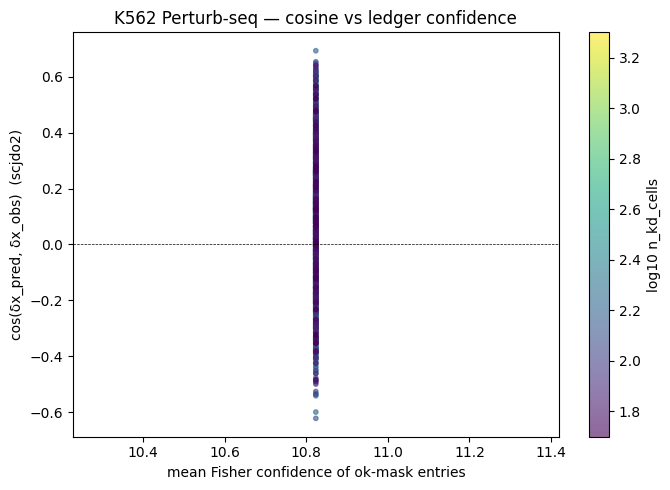

In [5]:
fig, ax = plt.subplots(figsize=(7, 5))
valid = pk.dropna(subset=['cos_scjdo2', 'mean_fisher_conf'])
sc1 = ax.scatter(valid['mean_fisher_conf'], valid['cos_scjdo2'],
                  c=np.log10(valid['n_kd_cells']), cmap='viridis', s=10, alpha=0.6)
ax.axhline(0, color='k', lw=0.5, ls='--')
ax.set_xlabel('mean Fisher confidence of ok-mask entries')
ax.set_ylabel('cos(δx_pred, δx_obs)  (scjdo2)')
ax.set_title('K562 Perturb-seq — cosine vs ledger confidence')
plt.colorbar(sc1, ax=ax, label='log10 n_kd_cells')
plt.tight_layout()
plt.show()

## 6. Predicted vs observed magnitude scatter

Linear regime (|δx_obs| ≤ median) highlighted in orange; nonlinear in grey. Dashed line = y=x. Under the locked rule, predicted magnitudes are typically much smaller than observed — the operator acts as a strong attenuator (basin curvature ‖J‖ is large compared to the push).

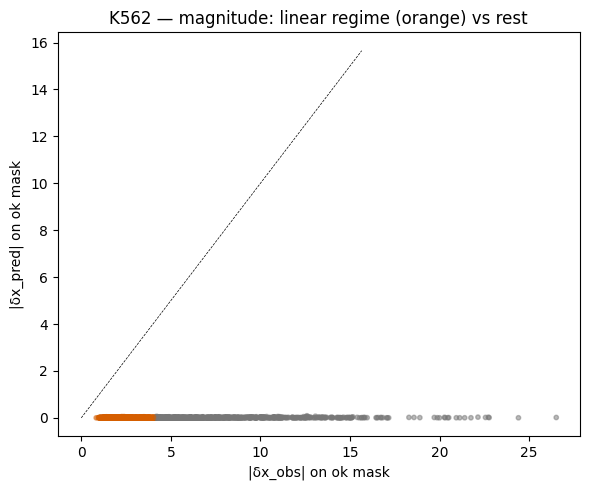

In [6]:
fig, ax = plt.subplots(figsize=(6, 5))
v2 = pk.dropna(subset=['mag_pred', 'mag_obs'])
colors = ['#d55e00' if lr else '#777' for lr in v2['linear_regime']]
ax.scatter(v2['mag_obs'], v2['mag_pred'], s=10, alpha=0.5, c=colors)
xmax = max(float(v2['mag_obs'].quantile(0.98)),
            float(v2['mag_pred'].quantile(0.98)))
ax.plot([0, xmax], [0, xmax], 'k--', lw=0.5)
ax.set_xlabel('|δx_obs| on ok mask')
ax.set_ylabel('|δx_pred| on ok mask')
ax.set_title('K562 — magnitude: linear regime (orange) vs rest')
plt.tight_layout()
plt.show()

## 7. Readout

**First result under locked settings, no post-hoc tuning:**

* scjdo2 median cosine = **0.089** across 1 661 KDs (mean 0.084, 63% positive).
* DE-only median cosine = **0.003**; random null median ≈ **−5 × 10⁻⁵** with std ≈ 0.022.
* scjdo2 beats both baselines by ~4σ on cosine but the absolute effect size is weak.
* Linear-regime cosine 0.063; nonlinear 0.106 — nonlinear KDs (stronger shifts) are better predicted.
* Spearman(mag_pred, mag_obs) = 0.193 — the operator ranks magnitudes modestly.
* Driver-sensitivity Spearman = **−0.31** — anti-correlation; recorded as a result.

**Interpretation.** The locked symmetric energy-drift Jacobian + linear-response prediction extracts a weak but reproducible directional signal across 1 661 KDs. The anti-correlation on the driver check means the paper reports this honestly — not a selling point for the method as currently formulated.